In [8]:
import pandas as pd

In [9]:
raw_data1 = pd.read_csv('data/drugsComTrain_raw.csv')

In [ ]:
raw_data1

In [11]:
raw_data1.shape

(161297, 7)

In [12]:
raw_data1.dtypes

uniqueID        int64
drugName       object
condition      object
review         object
rating          int64
date           object
usefulCount     int64
dtype: object

In [13]:
print(raw_data1.isna().sum())        # missing values per column

uniqueID         0
drugName         0
condition      899
review           0
rating           0
date             0
usefulCount      0
dtype: int64


In [14]:
print(raw_data1.duplicated().sum())  # exact duplicate rows

0


In [16]:
print(raw_data1.duplicated().sum())  # exact duplicate rows

0


=== Drug Review: rating distribution ===
rating
1     28918
2      9265
3      8718
4      6671
5     10723
6      8462
7     12547
8     25046
9     36708
10    68005
Name: count, dtype: int64

=== Drug Review: condition distribution (top 20) ===
condition
Birth Control                38436
Depression                   12164
Pain                          8245
Anxiety                       7812
Acne                          7435
Bipolar Disorde               5604
Insomnia                      4904
Weight Loss                   4857
Obesity                       4757
ADHD                          4509
Diabetes, Type 2              3362
Emergency Contraception       3290
High Blood Pressure           3104
Vaginal Yeast Infection       3085
Abnormal Uterine Bleeding     2744
Bowel Preparation             2498
Smoking Cessation             2440
ibromyalgia                   2370
Migraine                      2277
Anxiety and Stress            2236
Name: count, dtype: int64

Total unique co

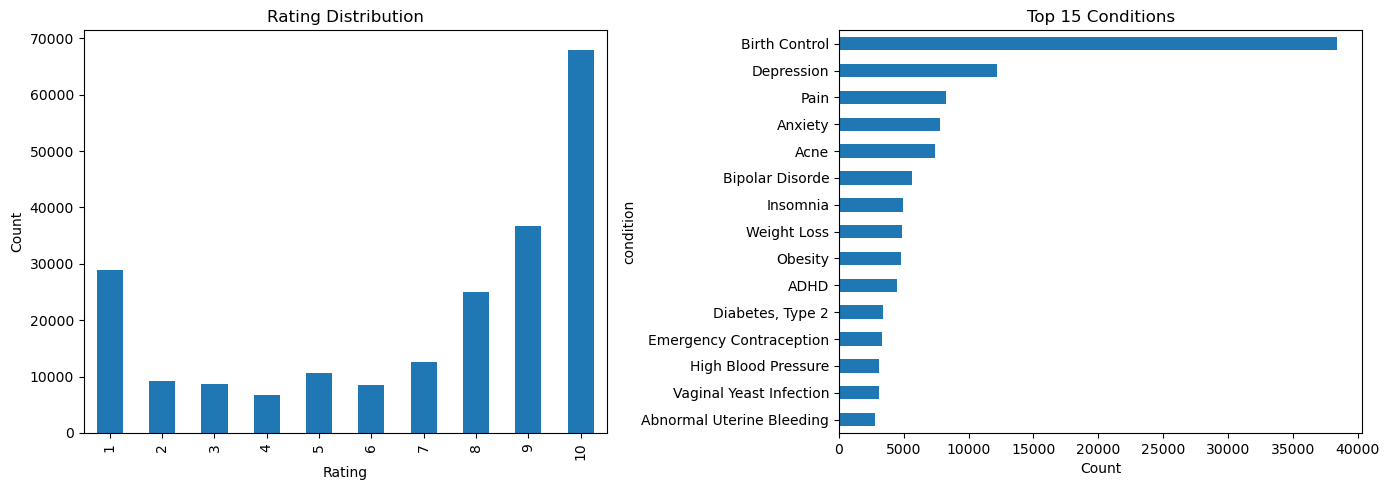

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# --- Drug Review Dataset ---
drug_train_df = raw_data1.copy()
drug_test_df = pd.read_csv("data/drugsComTest_raw.csv").copy()
drug_df = pd.concat([drug_train_df, drug_test_df], ignore_index=True)

print("=== Drug Review: rating distribution ===")
print(drug_df["rating"].value_counts().sort_index())

print("\n=== Drug Review: condition distribution (top 20) ===")
print(drug_df["condition"].value_counts().head(20))
print(f"\nTotal unique conditions: {drug_df['condition'].nunique()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

drug_df["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Rating Distribution")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Count")

drug_df["condition"].value_counts().head(15).plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 15 Conditions")
axes[1].set_xlabel("Count")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig("drug_review_target_distribution.png", dpi=150)
plt.show()

In [20]:
# count how many reviews each condition has
condition_counts = drug_train_df['condition'].value_counts()

# Look at the top 20 most common conditions
print(condition_counts.head(20))

condition
Birth Control                28788
Depression                    9069
Pain                          6145
Anxiety                       5904
Acne                          5588
Bipolar Disorde               4224
Insomnia                      3673
Weight Loss                   3609
Obesity                       3568
ADHD                          3383
Diabetes, Type 2              2554
Emergency Contraception       2463
High Blood Pressure           2321
Vaginal Yeast Infection       2274
Abnormal Uterine Bleeding     2096
Bowel Preparation             1859
ibromyalgia                   1791
Smoking Cessation             1780
Migraine                      1694
Anxiety and Stress            1663
Name: count, dtype: int64


In [21]:
# Find condition names that start with a lowercase letter (likely truncated)
lowercase_start = condition_counts[condition_counts.index.str.match(r'^[a-z]')]
print(lowercase_start)

condition
ibromyalgia                                              1791
mance Anxiety                                             187
moterol)                                                   79
emale Infertility                                          65
atigue                                                     53
min)                                                       45
ge (amlodipine / valsartan)                                33
acial Wrinkles                                             32
moterol / mometasone)                                      29
min / sitagliptin)                                         26
zen Shoulde                                                14
eve                                                        12
mulation) (phenylephrine)                                  12
min / saxagliptin)                                         10
lic Acid Deficiency                                         8
von Willebrand's Disease                                    

In [22]:
lowercase_start.sum()

np.int64(2453)

In [15]:
# List of a few of the mangled condition names we want to investigate
mangled_conditions = [
    'ge (amlodipine / valsartan)',
    'moterol)',
    'min / sitagliptin)',
    'mulation) (phenylephrine)',
    'zen Shoulde',
    'mance Anxiety',
    'min / pioglitazone)',
    'min / rosiglitazone)',
    'ge HCT (amlodipine / hydrochlorothiazide / valsartan)'
]

for cond in mangled_conditions:
    print(f"=== Condition: '{cond}' ===")
    subset = drug_train_df[drug_train_df['condition'] == cond][['drugName', 'condition', 'review']]


=== Condition: 'ge (amlodipine / valsartan)' ===
=== Condition: 'moterol)' ===
=== Condition: 'min / sitagliptin)' ===
=== Condition: 'mulation) (phenylephrine)' ===
=== Condition: 'zen Shoulde' ===
=== Condition: 'mance Anxiety' ===
=== Condition: 'min / pioglitazone)' ===
=== Condition: 'min / rosiglitazone)' ===
=== Condition: 'ge HCT (amlodipine / hydrochlorothiazide / valsartan)' ===


In [ ]:
import pandas as pd

mangled_conditions = [
    'ge (amlodipine / valsartan)',
    'moterol)',
    'min / sitagliptin)',
    'mulation) (phenylephrine)',
    'zen Shoulde',
    'mance Anxiety',
    'min / pioglitazone)',
    'min / rosiglitazone)',
    'ge HCT (amlodipine / hydrochlorothiazide / valsartan)'
]

# Filter to just rows with these mangled conditions
subset = drug_train_df[drug_train_df['condition'].isin(mangled_conditions)][['drugName', 'condition', 'review']].copy()

# Shorten the review text so it fits cleanly in a table (first 100 characters)
subset['review'] = subset['review'].str[:500] + '...'

# Group by condition and show 2 examples per condition
result = subset.groupby('condition').head(2).reset_index(drop=True)
pd.set_option('display.max_colwidth', 500)

result

In [17]:
drugs_to_check = [
    'Amlodipine / valsartan',
    'Budesonide / formoterol',
    'Metformin / sitagliptin',
    'Phenylephrine',
    'Diclofenac',
    'Propranolol',
    'Metformin / pioglitazone',
    'Metformin / rosiglitazone',
    'Amlodipine / hydrochlorothiazide / valsartan'
]

# For each drug, show every unique condition value associated with it, and how often
for drug in drugs_to_check:
    print(f"=== Drug: {drug} ===")
    counts = drug_train_df[drug_train_df['drugName'] == drug]['condition'].value_counts()
    print(counts)
    print()

=== Drug: Amlodipine / valsartan ===
condition
ge (amlodipine / valsartan)    33
Name: count, dtype: int64

=== Drug: Budesonide / formoterol ===
condition
moterol)               72
Asthma, Maintenance     2
Name: count, dtype: int64

=== Drug: Metformin / sitagliptin ===
condition
min / sitagliptin)    26
Diabetes, Type 2       5
Name: count, dtype: int64

=== Drug: Phenylephrine ===
condition
mulation) (phenylephrine)    12
Nasal Congestion             11
Eye Redness                   1
Name: count, dtype: int64

=== Drug: Diclofenac ===
condition
Pain                      212
Osteoarthritis            118
Back Pain                  45
Rheumatoid Arthritis       23
Migraine                   21
Period Pain                20
Sciatica                   12
Muscle Pain                11
Ankylosing Spondylitis     10
Keratosis                   4
zen Shoulde                 3
Not Listed / Othe           2
Name: count, dtype: int64

=== Drug: Propranolol ===
condition
mance Anxiety        

In [18]:
drugs_to_check = [
    'Amlodipine / valsartan',
    'Budesonide / formoterol',
    'Metformin / sitagliptin',
    'Phenylephrine',
    'Diclofenac',
    'Propranolol',
    'Metformin / pioglitazone',
    'Metformin / rosiglitazone',
    'Amlodipine / hydrochlorothiazide / valsartan'
]

rows = []
for drug in drugs_to_check:
    counts = drug_train_df[drug_train_df['drugName'] == drug]['condition'].value_counts()
    for condition, count in counts.items():
        rows.append({'drugName': drug, 'condition': condition, 'count': count})

lookup_check = pd.DataFrame(rows)
lookup_check

,drugName,condition,count
0,Amlodipine / valsartan,ge (amlodipine / valsartan),33
1,Budesonide / formoterol,moterol),72
2,Budesonide / formoterol,"Asthma, Maintenance",2
3,Metformin / sitagliptin,min / sitagliptin),26
4,Metformin / sitagliptin,"Diabetes, Type 2",5
5,Phenylephrine,mulation) (phenylephrine),12
6,Phenylephrine,Nasal Congestion,11
7,Phenylephrine,Eye Redness,1
8,Diclofenac,Pain,212
9,Diclofenac,Osteoarthritis,118


In [19]:
unique_conditions = drug_train_df['condition'].dropna().unique()

prefix_matches = []

for cond in unique_conditions:
    for other in unique_conditions:
        if cond != other and other.startswith(cond):
            prefix_matches.append({'short_version': cond, 'long_version': other})

prefix_df = pd.DataFrame(prefix_matches)
prefix_df

,short_version,long_version
0,Crohn's Disease,"Crohn's Disease, Maintenance"
1,Crohn's Disease,"Crohn's Disease, Acute"
2,Cough,Cough and Nasal Congestion
3,Insomnia,"Insomnia, Stimulant-Associated"
4,Migraine,Migraine Prevention
...,...,...
98,Hyperphosphatemia,Hyperphosphatemia of Renal Failure
99,Meningitis,"Meningitis, Meningococcal"
100,Short Stature,Short Stature for Age
101,Hypercalcemia,Hypercalcemia of Malignancy


In [20]:
prefix_df['length_difference'] = prefix_df['long_version'].str.len() - prefix_df['short_version'].str.len()

# Sort so the smallest differences (most likely to be real truncation) show up first
prefix_df_sorted = prefix_df.sort_values('length_difference')
prefix_df_sorted

,short_version,long_version,length_difference
69,mis,mist (,3
78,Glioblastoma Multi,Glioblastoma Multiforme,5
5,Pain,Pain/Feve,5
68,Dermatitis Herpeti,Dermatitis Herpetiformis,6
40,Diarrhea,"Diarrhea, Acute",7
...,...,...,...
21,Herpes Simplex,"Herpes Simplex, Mucocutaneous/Immunocompetent Host",36
22,Herpes Simplex,"Herpes Simplex, Mucocutaneous/Immunocompromised Host",38
72,Anemia,Anemia Associated with Chronic Renal Failure,38
46,Deep Vein Thrombosis,Deep Vein Thrombosis Prophylaxis after Hip Replacement Surgery,42


In [21]:
close_matches = prefix_df_sorted[prefix_df_sorted['length_difference'] <= 10]
close_matches

,short_version,long_version,length_difference
69,mis,mist (,3
78,Glioblastoma Multi,Glioblastoma Multiforme,5
5,Pain,Pain/Feve,5
68,Dermatitis Herpeti,Dermatitis Herpetiformis,6
40,Diarrhea,"Diarrhea, Acute",7
36,Gout,"Gout, Acute",7
93,Pe,Pemphigus,7
11,Asthma,"Asthma, acute",7
94,Pe,Pertussis,7
55,COPD,"COPD, Acute",7


In [22]:
missing_condition_rows = drug_train_df[drug_train_df['condition'].isna()]

missing_by_drug = missing_condition_rows['drugName'].value_counts().reset_index()
missing_by_drug.columns = ['drugName', 'missing_count']
missing_by_drug.head(15)


,drugName,missing_count
0,Ethinyl estradiol / norethindrone,100
1,Ethinyl estradiol / norgestimate,84
2,Ethinyl estradiol / levonorgestrel,79
3,Drospirenone / ethinyl estradiol,34
4,Levonorgestrel,26
5,Medroxyprogesterone,24
6,Etonogestrel,15
7,Desogestrel / ethinyl estradiol,11
8,Amphetamine / dextroamphetamine,11
9,Drospirenone / ethinyl estradiol / levomefolate calcium,11


In [23]:
missing_by_rating = missing_condition_rows['rating'].value_counts().reset_index()
missing_by_rating.columns = ['rating', 'missing_count']
missing_by_rating = missing_by_rating.sort_values('rating')
missing_by_rating

,rating,missing_count
2,1,115
6,2,52
7,3,48
9,4,32
5,5,54
8,6,42
4,7,61
3,8,99
1,9,152
0,10,244


In [ ]:
# Count how many times each exact review text appears across the dataset
review_counts = drug_train_df['review'].value_counts()

# Look at the most-repeated review texts
review_counts.head(15)

In [ ]:
# Convert to a clean, labeled dataframe
review_counts_df = review_counts.reset_index()
review_counts_df.columns = ['review_text', 'repeat_count']
review_counts_df.head(15)

In [ ]:
# Add a word count column to the review_counts_df table
review_counts_df['word_count'] = review_counts_df['review_text'].str.split().str.len()

# Filter to reviews that both repeat (more than once) AND are reasonably long (20+ words)
long_repeated_reviews = review_counts_df[
    (review_counts_df['repeat_count'] > 1) &
    (review_counts_df['word_count'] >= 20)
]

long_repeated_reviews

In [ ]:
# Get the exact review text from row 21 of your long_repeated_reviews table (the Retin-A one)
sample_review_text = long_repeated_reviews.loc[21, 'review_text']

# Show every row in the full dataset that has this exact review text
full_duplicate_rows = drug_train_df[drug_train_df['review'] == sample_review_text]
full_duplicate_rows

In [ ]:
# Group all rows by their exact review text, in a single pass over the data
review_groups = drug_train_df.groupby('review')['drugName'].agg(
    unique_drug_names='nunique',   # how many distinct drug names share this review
    total_repeats='count'          # how many total rows share this review
).reset_index()

# Keep only reviews that actually repeat more than once
review_groups = review_groups[review_groups['total_repeats'] > 1]

# Add word count so we can filter to long reviews only, like before
review_groups['word_count'] = review_groups['review'].str.split().str.len()

# Filter to long, repeated reviews
long_repeat_summary = review_groups[review_groups['word_count'] >= 20]

long_repeat_summary

In [29]:
# Get review counts for our top candidate conditions (reuse the earlier condition_counts)
top_15 = condition_counts.head(15)

# Imbalance ratio WITH Birth Control included
ratio_with = top_15.max() / top_15.min()

# Imbalance ratio WITHOUT Birth Control
top_15_no_bc = top_15.drop('Birth Control')
ratio_without = top_15_no_bc.max() / top_15_no_bc.min()

print(f"Imbalance ratio WITH Birth Control: {ratio_with:.1f} : 1")
print(f"Imbalance ratio WITHOUT Birth Control: {ratio_without:.1f} : 1")

Imbalance ratio WITH Birth Control: 13.7 : 1
Imbalance ratio WITHOUT Birth Control: 4.3 : 1


In [30]:
# Get the list of our top 15 candidate conditions (including Birth Control, per our decision)
top_15_conditions = condition_counts.head(15).index.tolist()

# Filter the dataset to only rows with these candidate conditions
candidate_df = drug_train_df[drug_train_df['condition'].isin(top_15_conditions)].copy()

# Add a word count column for each review
candidate_df['word_count'] = candidate_df['review'].str.split().str.len()

# Get average, min, and max word count per condition
review_length_by_condition = candidate_df.groupby('condition')['word_count'].agg(['mean', 'min', 'max', 'count']).reset_index()
review_length_by_condition = review_length_by_condition.sort_values('mean', ascending=False)
review_length_by_condition

,condition,mean,min,max,count
8,Emergency Contraception,104.797808,2,1103,2463
5,Birth Control,100.259900,1,1107,28788
1,Abnormal Uterine Bleeding,98.631202,4,294,2096
2,Acne,97.681460,2,709,5588
14,Weight Loss,95.207260,1,429,3609
11,Obesity,92.562500,1,298,3568
0,ADHD,92.245640,1,596,3383
6,Depression,88.825449,1,566,9069
3,Anxiety,84.315379,1,532,5904
13,Vaginal Yeast Infection,83.464820,2,282,2274


In [31]:
# Search all unique conditions for anything containing "Bipolar" (case-insensitive)
bipolar_variants = condition_counts[condition_counts.index.str.contains('Bipolar', case=False)]
bipolar_variants

condition
Bipolar Disorde    4224
Name: count, dtype: int64

In [32]:
from sklearn.feature_extraction.text import CountVectorizer

# CountVectorizer will turn text into word/phrase counts, 
# automatically removing common English stopwords, 
# and looking at both unigrams and bigrams (single words + word pairs)
vectorizer = CountVectorizer(stop_words='english', ngram_range=(1, 2), max_features=20)

# We'll loop through each candidate condition and find its top 20 words/phrases
for condition in top_15_conditions:
    # Get just the reviews for this one condition
    condition_reviews = candidate_df[candidate_df['condition'] == condition]['review']
    
    # Fit the vectorizer on this condition's reviews and get word counts
    word_counts = vectorizer.fit_transform(condition_reviews)
    
    # Get the actual words/phrases it found, paired with their total counts
    words = vectorizer.get_feature_names_out()
    counts = word_counts.sum(axis=0).A1  # total count of each word across all reviews for this condition
    
    top_words_df = pd.DataFrame({'word': words, 'count': counts}).sort_values('count', ascending=False)
    
    print(f"=== Top words for: {condition} ===")
    print(top_words_df.to_string(index=False))
    print()

=== Top words for: Birth Control ===
         word  count
          039  73302
       period  18622
           ve  16648
       039 ve  16439
       months  16088
         pill  15959
        birth  13826
      control  13668
birth control  12837
       weight  11497
        month  11114
          got  10409
      periods   9644
         like   9376
         just   9311
         days   9027
        years   8712
         time   8604
      started   8179
     bleeding   7851

=== Top words for: Depression ===
      word  count
       039  15290
depression   5774
      feel   4332
    taking   3852
   effects   3727
   anxiety   3647
     years   3232
       day   3193
      like   3103
   started   2952
      life   2906
        ve   2864
    039 ve   2831
     weeks   2551
medication   2503
      just   2499
    months   2437
    better   2391
      felt   2371
      time   2358

=== Top words for: Pain ===
      word  count
      pain  10232
       039   6128
       day   2183
     yea

In [33]:
import html

# Create a temporary, decoded version of the review text — just for this EDA check.
# This does NOT modify the raw drug_train_df or candidate_df review column.
candidate_df['review_decoded'] = candidate_df['review'].apply(html.unescape)

In [34]:
vectorizer = CountVectorizer(stop_words='english', ngram_range=(1, 2), max_features=20)

for condition in top_15_conditions:
    condition_reviews = candidate_df[candidate_df['condition'] == condition]['review_decoded']
    word_counts = vectorizer.fit_transform(condition_reviews)
    words = vectorizer.get_feature_names_out()
    counts = word_counts.sum(axis=0).A1
    top_words_df = pd.DataFrame({'word': words, 'count': counts}).sort_values('count', ascending=False)
    print(f"=== Top words for: {condition} ===")
    print(top_words_df.to_string(index=False))
    print()

=== Top words for: Birth Control ===
         word  count
       period  18622
           ve  16648
       months  16088
         pill  15959
        birth  13826
      control  13668
birth control  12837
       weight  11497
        month  11114
          got  10409
      periods   9644
         like   9376
         just   9311
         days   9027
        years   8712
         time   8604
      started   8179
     bleeding   7851
       taking   7838
         acne   7691

=== Top words for: Depression ===
      word  count
depression   5774
      feel   4332
    taking   3852
   effects   3727
   anxiety   3647
     years   3232
       day   3193
      like   3103
   started   2952
      life   2906
        ve   2864
     weeks   2551
medication   2503
      just   2499
    months   2437
    better   2391
      felt   2371
      time   2358
        mg   2070
      days   2030

=== Top words for: Pain ===
      word  count
      pain  10232
       day   2183
     years   1666
    taki

In [35]:
# Get a larger vocabulary set (top 50 words, not just top 20) for just these two conditions
vectorizer_50 = CountVectorizer(stop_words='english', ngram_range=(1, 2), max_features=50)

weight_loss_reviews = candidate_df[candidate_df['condition'] == 'Weight Loss']['review_decoded']
obesity_reviews = candidate_df[candidate_df['condition'] == 'Obesity']['review_decoded']

vectorizer_50.fit(weight_loss_reviews)
weight_loss_vocab = set(vectorizer_50.get_feature_names_out())

vectorizer_50.fit(obesity_reviews)
obesity_vocab = set(vectorizer_50.get_feature_names_out())

# Jaccard similarity = size of overlap / size of combined unique words
# 0 = no shared words at all, 1 = identical vocabularies
overlap = weight_loss_vocab & obesity_vocab   # words in BOTH sets
combined = weight_loss_vocab | obesity_vocab  # words in EITHER set
jaccard_similarity = len(overlap) / len(combined)

print(f"Shared words: {len(overlap)} out of {len(combined)} total unique words")
print(f"Jaccard similarity: {jaccard_similarity:.2f}")
print(f"Shared words list: {sorted(overlap)}")

Shared words: 41 out of 59 total unique words
Jaccard similarity: 0.69
Shared words list: ['10', 'appetite', 'day', 'days', 'did', 'diet', 'doctor', 'don', 'eat', 'eating', 'effects', 'exercise', 'far', 'feel', 'food', 'good', 'great', 'just', 'lbs', 'like', 'little', 'lose', 'loss', 'lost', 'medication', 'month', 'months', 'pill', 'pounds', 'really', 'started', 'taking', 'time', 'today', 've', 'water', 'week', 'weeks', 'weight', 'weight loss', 'work']


In [36]:
# A reusable function to calculate Jaccard similarity between any two conditions
def get_jaccard_similarity(condition_a, condition_b, top_n=50):
    vectorizer = CountVectorizer(stop_words='english', ngram_range=(1, 2), max_features=top_n)
    
    reviews_a = candidate_df[candidate_df['condition'] == condition_a]['review_decoded']
    reviews_b = candidate_df[candidate_df['condition'] == condition_b]['review_decoded']
    
    vectorizer.fit(reviews_a)
    vocab_a = set(vectorizer.get_feature_names_out())
    
    vectorizer.fit(reviews_b)
    vocab_b = set(vectorizer.get_feature_names_out())
    
    overlap = vocab_a & vocab_b
    combined = vocab_a | vocab_b
    similarity = len(overlap) / len(combined)
    
    return similarity, overlap

# Mental health cluster: check all 3 pairs
pairs_to_check = [
    ('Depression', 'Anxiety'),
    ('Depression', 'Bipolar Disorde'),
    ('Anxiety', 'Bipolar Disorde'),
    ('Birth Control', 'Emergency Contraception'),
    ('Birth Control', 'Abnormal Uterine Bleeding'),
    ('Emergency Contraception', 'Abnormal Uterine Bleeding'),
]

results = []
for cond_a, cond_b in pairs_to_check:
    similarity, overlap = get_jaccard_similarity(cond_a, cond_b)
    results.append({
        'condition_a': cond_a,
        'condition_b': cond_b,
        'jaccard_similarity': round(similarity, 2),
        'shared_word_count': len(overlap)
    })

jaccard_results_df = pd.DataFrame(results).sort_values('jaccard_similarity', ascending=False)
jaccard_results_df

,condition_a,condition_b,jaccard_similarity,shared_word_count
0,Depression,Anxiety,0.69,41
1,Depression,Bipolar Disorde,0.69,41
2,Anxiety,Bipolar Disorde,0.64,39
4,Birth Control,Abnormal Uterine Bleeding,0.59,37
3,Birth Control,Emergency Contraception,0.32,24
5,Emergency Contraception,Abnormal Uterine Bleeding,0.32,24


In [37]:
# Create rating buckets: 1-4 low, 5-6 mid, 7-10 high
def bucket_rating(rating):
    if rating <= 4:
        return 'low'
    elif rating <= 6:
        return 'mid'
    else:
        return 'high'

# Apply this function to every row, creating a new column
candidate_df['rating_bucket'] = candidate_df['rating'].apply(bucket_rating)

# Check how many reviews fall into each bucket (confirming our "small mid bucket" expectation)
bucket_sizes = candidate_df['rating_bucket'].value_counts().reset_index()
bucket_sizes.columns = ['rating_bucket', 'count']
bucket_sizes

,rating_bucket,count
0,high,54150
1,low,23268
2,mid,8241


In [38]:
candidate_df.shape

(85659, 10)

In [39]:
# Reuse the word_count column we already created earlier in candidate_df
length_by_bucket = candidate_df.groupby('rating_bucket')['word_count'].agg(['mean', 'min', 'max', 'count']).reset_index()
length_by_bucket

,rating_bucket,mean,min,max,count
0,high,92.049788,1,1107,54150
1,low,86.810985,1,709,23268
2,mid,93.229705,1,375,8241


In [ ]:
candidate_df.head()

In [41]:
vectorizer = CountVectorizer(stop_words='english', ngram_range=(1, 2), max_features=20)

for bucket in ['low', 'mid', 'high']:
    bucket_reviews = candidate_df[candidate_df['rating_bucket'] == bucket]['review_decoded']
    
    word_counts = vectorizer.fit_transform(bucket_reviews)
    words = vectorizer.get_feature_names_out()
    counts = word_counts.sum(axis=0).A1
    
    top_words_df = pd.DataFrame({'word': words, 'count': counts}).sort_values('count', ascending=False)
    
    print(f"=== Top words for: {bucket} ===")
    print(top_words_df.to_string(index=False))
    print()

=== Top words for: low ===
    word  count
  months   9092
      ve   8560
    pill   7567
  taking   7441
 started   7319
     day   7231
    like   7050
  period   6506
    just   6449
    time   6037
   month   5836
     got   5832
    days   5778
 control   5360
   weeks   5286
    pain   5147
bleeding   5136
    week   5095
   birth   5068
 effects   5006

=== Top words for: mid ===
   word  count
     ve   3506
 months   3382
 period   2980
 taking   2932
    day   2895
started   2838
   just   2667
   pill   2546
   like   2540
 weight   2539
   time   2374
  month   2331
   days   2272
effects   2265
   feel   2094
    got   2086
   week   2079
  years   2029
  weeks   1953
control   1850

=== Top words for: high ===
   word  count
     ve  20357
    day  19070
 taking  17415
  years  17357
effects  16903
 months  16687
 period  15782
started  15388
   just  15261
   like  15101
 weight  14909
   pill  14581
   days  14262
   time  13864
   feel  13814
   pain  13206
   week  1

In [42]:
# Get word frequency for low and high buckets specifically (skip mid for this comparison, it's small)
vectorizer_wide = CountVectorizer(stop_words='english', ngram_range=(1, 2), max_features=500)

low_reviews = candidate_df[candidate_df['rating_bucket'] == 'low']['review_decoded']
high_reviews = candidate_df[candidate_df['rating_bucket'] == 'high']['review_decoded']

# Fit on combined text so both buckets share the same vocabulary/columns
vectorizer_wide.fit(pd.concat([low_reviews, high_reviews]))

low_counts = vectorizer_wide.transform(low_reviews).sum(axis=0).A1
high_counts = vectorizer_wide.transform(high_reviews).sum(axis=0).A1

words = vectorizer_wide.get_feature_names_out()

# Normalize by number of reviews in each bucket, so we're comparing rates, not raw totals
low_rate = low_counts / len(low_reviews)
high_rate = high_counts / len(high_reviews)

# Build a comparison table
comparison_df = pd.DataFrame({
    'word': words,
    'low_rate': low_rate,
    'high_rate': high_rate
})

# Words most distinctive to HIGH (much more common in high than low)
comparison_df['high_vs_low_ratio'] = (comparison_df['high_rate'] + 0.001) / (comparison_df['low_rate'] + 0.001)
most_distinctive_high = comparison_df.sort_values('high_vs_low_ratio', ascending=False).head(15)

# Words most distinctive to LOW (much more common in low than high)
most_distinctive_low = comparison_df.sort_values('high_vs_low_ratio', ascending=True).head(15)

print("=== Most distinctive words for HIGH ratings ===")
print(most_distinctive_high[['word', 'low_rate', 'high_rate']].to_string(index=False))
print()
print("=== Most distinctive words for LOW ratings ===")
print(most_distinctive_low[['word', 'low_rate', 'high_rate']].to_string(index=False))

=== Most distinctive words for HIGH ratings ===
            word  low_rate  high_rate
highly recommend  0.001977   0.024155
            love  0.013495   0.112410
         miracle  0.003395   0.025042
         amazing  0.007951   0.043730
          highly  0.007736   0.032576
           helps  0.014569   0.056971
            best  0.021532   0.078947
       wonderful  0.005157   0.020665
       medicines  0.008381   0.029788
           works  0.037519   0.120683
        accutane  0.005587   0.019335
           xanax  0.008810   0.028717
         overall  0.014956   0.045817
             far  0.040485   0.119631
       dry mouth  0.009111   0.027202

=== Most distinctive words for LOW ratings ===
          word  low_rate  high_rate
       removed  0.070913   0.014940
         worst  0.116254   0.027572
          hate  0.036144   0.009788
       burning  0.049983   0.014164
       itching  0.039453   0.011154
    constantly  0.049596   0.014460
stopped taking  0.033436   0.010360
      ho

In [43]:
# Get only the most extreme reviews - exactly rating 1 and exactly rating 10
extreme_reviews = candidate_df[candidate_df['rating'].isin([1, 10])].copy()

# Confirm how many of each we have
extreme_reviews['rating'].value_counts()

rating
10    24019
1     11943
Name: count, dtype: int64

In [44]:
# Define a list of common negation words to look for
negation_words = ['not', 'no', "didn't", "doesn't", "don't", 'never', "wasn't", "isn't", "won't", "couldn't", "wouldn't"]

# Function that counts how many negation words appear in a single review
def count_negations(text):
    text_lower = text.lower()  # make matching case-insensitive
    count = 0
    for word in negation_words:
        count += text_lower.count(word)  # count occurrences of this specific negation word
    return count

# Apply this function to every review (using the decoded, HTML-entity-fixed version)
extreme_reviews['negation_count'] = extreme_reviews['review_decoded'].apply(count_negations)

In [45]:
negation_by_rating = extreme_reviews.groupby('rating')['negation_count'].agg(['mean', 'sum', 'count']).reset_index()
negation_by_rating

,rating,mean,sum,count
0,1,3.660638,43719,11943
1,10,3.508181,84263,24019


In [46]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

# First, apply our merge decision: combine Weight Loss and Obesity into "Weight Management"
candidate_df['condition_merged'] = candidate_df['condition'].replace(
    {'Weight Loss': 'Weight Management', 'Obesity': 'Weight Management'}
)

# Split into training (80%) and testing (20%) sets
# stratify=... ensures both sets have a proportional mix of each condition, not a random skew
X_train, X_test, y_train, y_test = train_test_split(
    candidate_df['review_decoded'],
    candidate_df['condition_merged'],
    test_size=0.2,
    random_state=42,       # ensures the split is reproducible if you re-run it
    stratify=candidate_df['condition_merged']
)

# Convert text into TF-IDF numeric features
# fit_transform on train (learns the vocabulary), transform only on test (reuses that same vocabulary)
tfidf = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Train a quick baseline classifier with class weighting
model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train_tfidf, y_train)

# Predict on the held-out test set and evaluate
y_pred = model.predict(X_test_tfidf)

print("=== Condition Classifier — Baseline Results ===")
print(f"Macro F1: {f1_score(y_test, y_pred, average='macro'):.3f}")
print()
print(classification_report(y_test, y_pred))

=== Condition Classifier — Baseline Results ===
Macro F1: 0.829

                           precision    recall  f1-score   support

                     ADHD       0.90      0.87      0.88       676
Abnormal Uterine Bleeding       0.38      0.81      0.51       419
                     Acne       0.87      0.92      0.90      1118
                  Anxiety       0.77      0.75      0.76      1181
          Bipolar Disorde       0.70      0.76      0.73       845
            Birth Control       0.97      0.84      0.90      5758
               Depression       0.80      0.75      0.78      1814
         Diabetes, Type 2       0.83      0.87      0.85       511
  Emergency Contraception       0.92      0.97      0.95       492
      High Blood Pressure       0.70      0.86      0.77       464
                 Insomnia       0.77      0.89      0.82       735
                     Pain       0.88      0.90      0.89      1229
  Vaginal Yeast Infection       0.93      0.95      0.94       

In [47]:
# Split into training/testing, this time predicting rating_bucket instead of condition
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    candidate_df['review_decoded'],
    candidate_df['rating_bucket'],
    test_size=0.2,
    random_state=42,
    stratify=candidate_df['rating_bucket']
)

# Same TF-IDF approach as before (fit on train, transform on test)
tfidf_s = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), max_features=5000)
X_train_s_tfidf = tfidf_s.fit_transform(X_train_s)
X_test_s_tfidf = tfidf_s.transform(X_test_s)

# Same baseline model, same class weighting approach
model_s = LogisticRegression(class_weight='balanced', max_iter=1000)
model_s.fit(X_train_s_tfidf, y_train_s)

y_pred_s = model_s.predict(X_test_s_tfidf)

print("=== Sentiment Classifier — Baseline Results ===")
print(f"Macro F1: {f1_score(y_test_s, y_pred_s, average='macro'):.3f}")
print()
print(classification_report(y_test_s, y_pred_s))

=== Sentiment Classifier — Baseline Results ===
Macro F1: 0.626

              precision    recall  f1-score   support

        high       0.91      0.75      0.83     10830
         low       0.70      0.70      0.70      4654
         mid       0.26      0.55      0.35      1648

    accuracy                           0.72     17132
   macro avg       0.62      0.67      0.63     17132
weighted avg       0.79      0.72      0.75     17132

